# UTS Pembelajaran Mesin 2026 - Decision Tree & KNN
Dataset: Counter Strike 2   
NIM: **202531077_Syalwa Melza Eka Fitri**

## Import library

In [1]:
# 202531077_Syalwa Melza Eka Fitri
nim = "202531077_Syalwa Melza Eka Fitri"
print("NIM :", nim)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

NIM : 202531077_Syalwa Melza Eka Fitri


## Membaca dataset

In [2]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
df = pd.read_csv("03_counter_strike_2.csv")
df.head()

NIM : 202531077_Syalwa Melza Eka Fitri


,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT


## Melihat informasi dataset (EDA)

In [3]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
df.info()
df.describe()

NIM : 202531077_Syalwa Melza Eka Fitri
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   str    
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   str    
dtypes: bool(1), float64(11), str(2)
memory usage: 224.8 KB


,time_left,ct_score,t_score,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets
count,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000
mean,95.630205,6.840000,6.28850,406.170500,402.987500,306.749000,309.54450,7867.350000,12377.600000,1.821500,3.009500
std,53.734491,4.233599,4.19059,137.616258,137.699186,172.857221,168.68957,9017.491838,12209.581798,1.774884,1.960952
min,0.050000,0.000000,0.00000,2.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,54.910000,3.000000,3.00000,315.750000,328.750000,188.000000,190.00000,1200.000000,1700.000000,0.000000,1.000000
50%,94.910000,7.000000,6.00000,500.000000,500.000000,300.000000,362.00000,4000.000000,9075.000000,1.000000,4.000000
75%,156.425000,10.000000,10.00000,500.000000,500.000000,488.000000,467.00000,11762.500000,19250.000000,3.000000,5.000000
max,175.000000,15.000000,15.00000,500.000000,500.000000,500.000000,500.00000,58050.000000,67700.000000,5.000000,5.000000


## Cek data kosong dan data duplikat

In [4]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
print("Data kosong:")
print(df.isnull().sum())
print("Data duplikat:", df.duplicated().sum())

NIM : 202531077_Syalwa Melza Eka Fitri
Data kosong:
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted    0
ct_health       0
t_health        0
ct_armor        0
t_armor         0
ct_money        0
t_money         0
ct_helmets      0
t_helmets       0
round_winner    0
dtype: int64
Data duplikat: 39


## Melihat sebaran kelas round_winner

NIM : 202531077_Syalwa Melza Eka Fitri


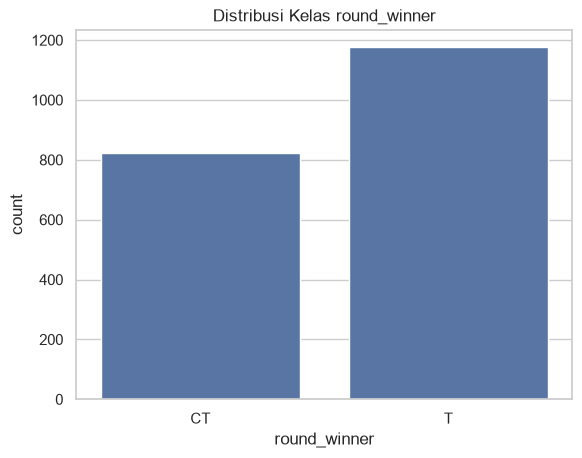

round_winner
T     1176
CT     824
Name: count, dtype: int64


In [5]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
sns.countplot(x="round_winner", data=df)
plt.title("Distribusi Kelas round_winner")
plt.show()
print(df["round_winner"].value_counts())

## Boxplot hubungan fitur dengan pemenang

NIM : 202531077_Syalwa Melza Eka Fitri


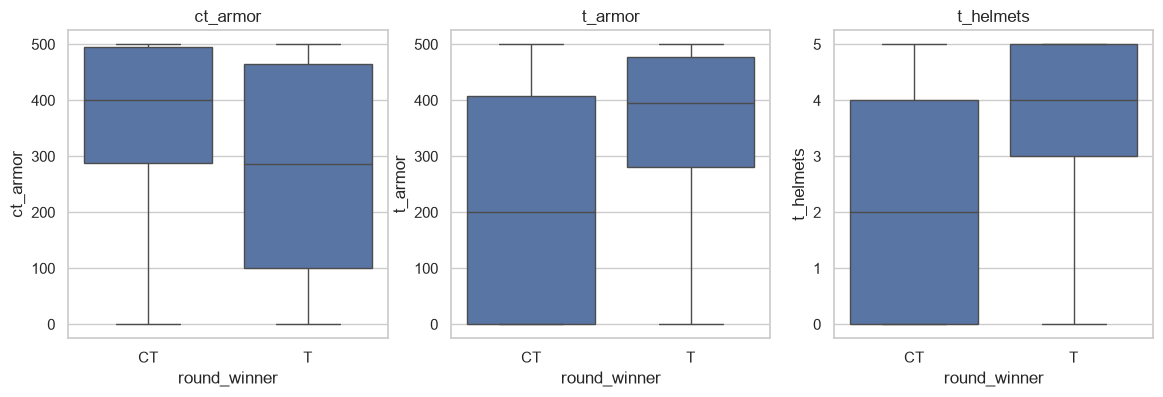

In [6]:
#202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.boxplot(x="round_winner", y="ct_armor", data=df)
plt.title("ct_armor")

plt.subplot(1, 3, 2)
sns.boxplot(x="round_winner", y="t_armor", data=df)
plt.title("t_armor")

plt.subplot(1, 3, 3)
sns.boxplot(x="round_winner", y="t_helmets", data=df)
plt.title("t_helmets")

plt.show()

## Heatmap korelasi

NIM : 202531077_Syalwa Melza Eka Fitri


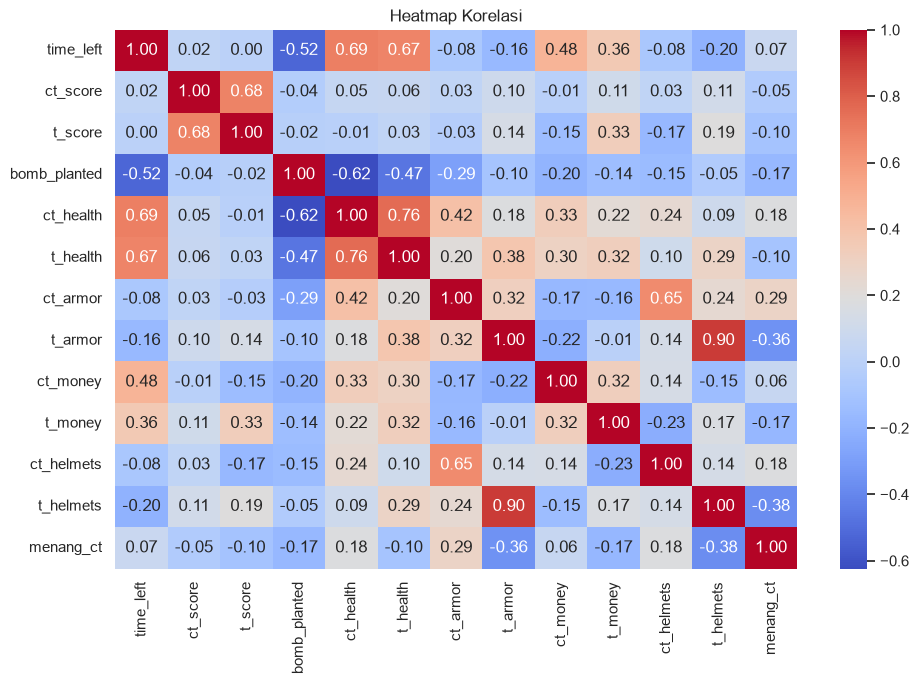

In [7]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
df_korelasi = df.copy()
df_korelasi["bomb_planted"] = df_korelasi["bomb_planted"].astype(int)
df_korelasi["menang_ct"] = (df_korelasi["round_winner"] == "CT").astype(int)
angka = df_korelasi.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(11, 7))
sns.heatmap(angka.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Heatmap Korelasi")
plt.show()

## Preprocessing: hapus duplikat dan ubah data jadi angka

In [8]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
df = df.drop_duplicates()
df["bomb_planted"] = df["bomb_planted"].astype(int)
df = pd.get_dummies(df, columns=["map"], dtype=int)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["round_winner"] = le.fit_transform(df["round_winner"])
for i, label in enumerate(le.classes_):
    print(f"{i} = {label}")

print("Jumlah data sekarang:", df.shape)
df.head()

NIM : 202531077_Syalwa Melza Eka Fitri
0 = CT
1 = T
Jumlah data sekarang: (1961, 20)


,time_left,ct_score,t_score,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner,map_de_dust2,map_de_inferno,map_de_mirage,map_de_nuke,map_de_overpass,map_de_train,map_de_vertigo
0,175.00,0.0,0.0,0,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,0,1,0,0,0,0,0,0
1,156.03,0.0,0.0,0,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,0,1,0,0,0,0,0,0
2,96.03,0.0,0.0,0,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,0,1,0,0,0,0,0,0
3,76.03,0.0,0.0,0,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,0,1,0,0,0,0,0,0
4,174.97,1.0,0.0,0,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,0,1,0,0,0,0,0,0


## Memisahkan fitur (x) dan target (y)

In [9]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
x = df.drop("round_winner", axis=1)
y = df["round_winner"]
print("Bentuk x:", x.shape)
print("Bentuk y:", y.shape)

NIM : 202531077_Syalwa Melza Eka Fitri
Bentuk x: (1961, 19)
Bentuk y: (1961,)


## Membagi data latih dan data uji

In [10]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=1, stratify=y)
print("x_train:", x_train.shape)
print("x_test :", x_test.shape)

NIM : 202531077_Syalwa Melza Eka Fitri
x_train: (1470, 19)
x_test : (491, 19)


## Decision Tree - model pertama (pengaturan bawaan)

In [11]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt1 = DecisionTreeClassifier(random_state=1)
dt1.fit(x_train, y_train)

print("Kedalaman pohon:", dt1.get_depth())
print("Akurasi data latih:", accuracy_score(y_train, dt1.predict(x_train)))
print("Akurasi data uji  :", accuracy_score(y_test, dt1.predict(x_test)))

NIM : 202531077_Syalwa Melza Eka Fitri
Kedalaman pohon: 16
Akurasi data latih: 0.9993197278911564
Akurasi data uji  : 0.8574338085539714


## Decision Tree - mencoba beberapa max_depth

NIM : 202531077_Syalwa Melza Eka Fitri


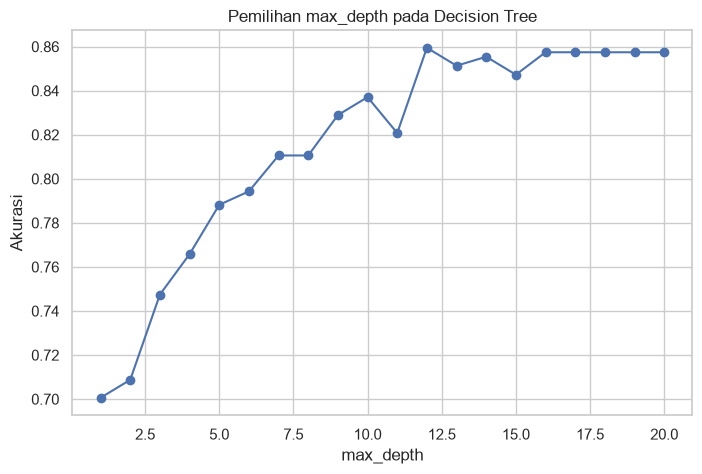

max_depth terbaik: 12
akurasi: 0.8594704684317719


In [12]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
depths = range(1, 21)
akurasi_dt = []

for d in depths:
    model = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=1)
    model.fit(x_train, y_train)
    akurasi_dt.append(accuracy_score(y_test, model.predict(x_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, akurasi_dt, marker="o")
plt.xlabel("max_depth")
plt.ylabel("Akurasi")
plt.title("Pemilihan max_depth pada Decision Tree")
plt.show()

best_depth = depths[akurasi_dt.index(max(akurasi_dt))]
print("max_depth terbaik:", best_depth)
print("akurasi:", max(akurasi_dt))

## Decision Tree - model akhir dan akurasi

In [13]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.metrics import classification_report

dt = DecisionTreeClassifier(criterion="gini", max_depth=best_depth, random_state=1)
dt.fit(x_train, y_train)
pred_dt = dt.predict(x_test)

akurasi_dt_final = accuracy_score(y_test, pred_dt)
print("Akurasi Decision Tree:", akurasi_dt_final)
print(classification_report(y_test, pred_dt, target_names=le.classes_))

NIM : 202531077_Syalwa Melza Eka Fitri
Akurasi Decision Tree: 0.8594704684317719
              precision    recall  f1-score   support

          CT       0.83      0.83      0.83       202
           T       0.88      0.88      0.88       289

    accuracy                           0.86       491
   macro avg       0.85      0.86      0.86       491
weighted avg       0.86      0.86      0.86       491



## Decision Tree - gambar pohon 

NIM : 202531077_Syalwa Melza Eka Fitri


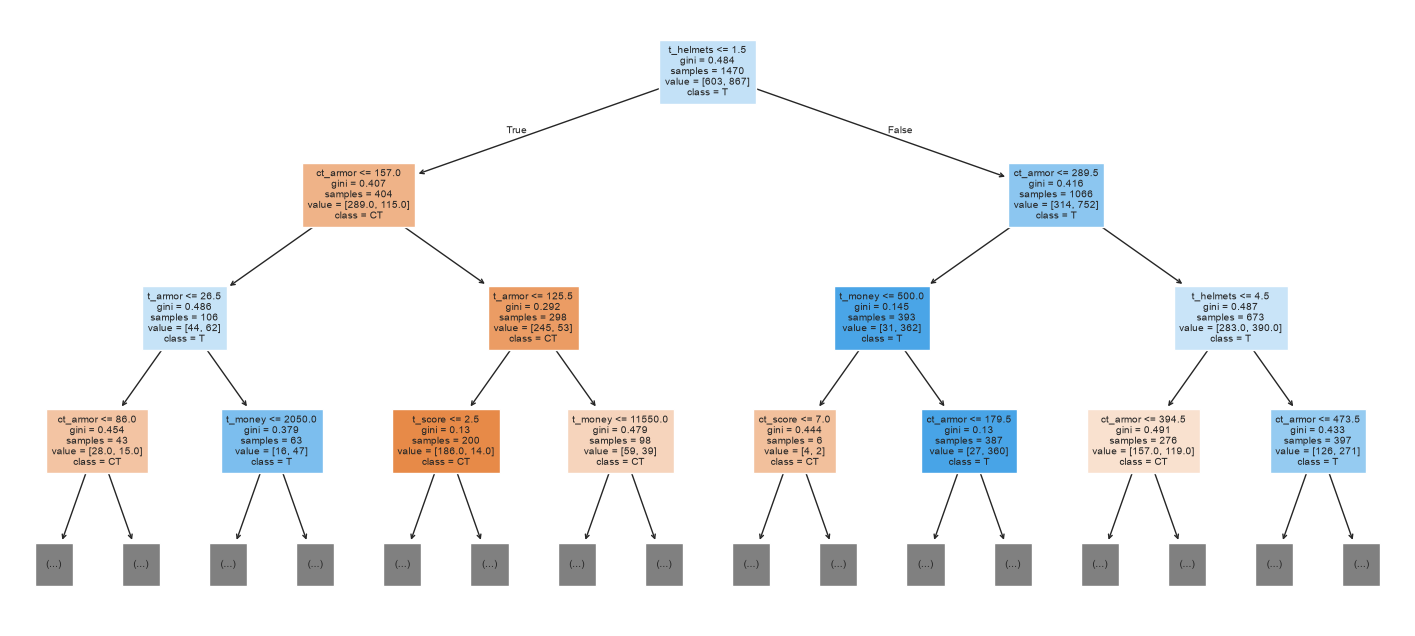

t_helmets    0.191378
ct_armor     0.181863
ct_money     0.105795
t_money      0.089228
t_armor      0.088854
ct_score     0.063157
dtype: float64


In [14]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn import tree

plt.subplots(figsize=(18, 8))
tree.plot_tree(dt, max_depth=3, feature_names=x.columns, class_names=le.classes_, filled=True, fontsize=7)
plt.show()

penting = pd.Series(dt.feature_importances_, index=x.columns).sort_values(ascending=False)
print(penting.head(6))

## KNN - scaling data

In [15]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Rata-rata kolom ct_money sebelum scaling:", round(x_train["ct_money"].mean(), 1))
print("Rata-rata kolom ct_money sesudah scaling:", round(x_train_scaled[:, list(x.columns).index("ct_money")].mean(), 4))

NIM : 202531077_Syalwa Melza Eka Fitri
Rata-rata kolom ct_money sebelum scaling: 7704.9
Rata-rata kolom ct_money sesudah scaling: 0.0


## KNN - model pertama dengan k = 7

In [16]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.neighbors import KNeighborsClassifier

knn1 = KNeighborsClassifier(n_neighbors=7)
knn1.fit(x_train_scaled, y_train)
pred_knn1 = knn1.predict(x_test_scaled)
print("Akurasi KNN (k=7):", accuracy_score(y_test, pred_knn1))

NIM : 202531077_Syalwa Melza Eka Fitri
Akurasi KNN (k=7): 0.8228105906313645


## KNN - mencari nilai k terbaik

NIM : 202531077_Syalwa Melza Eka Fitri


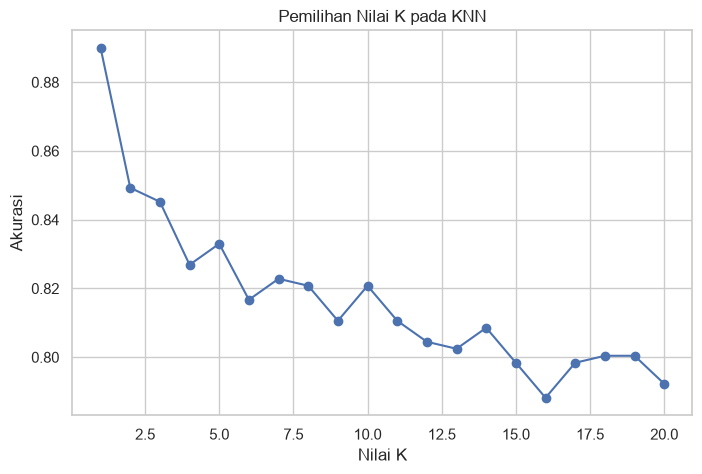

k terbaik: 1
akurasi: 0.890020366598778


In [17]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
k_values = range(1, 21)
akurasi_knn = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_scaled, y_train)
    akurasi_knn.append(accuracy_score(y_test, model.predict(x_test_scaled)))

plt.figure(figsize=(8, 5))
plt.plot(k_values, akurasi_knn, marker="o")
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.title("Pemilihan Nilai K pada KNN")
plt.grid(True)
plt.show()

best_k = k_values[akurasi_knn.index(max(akurasi_knn))]
print("k terbaik:", best_k)
print("akurasi:", max(akurasi_knn))

## KNN - model akhir dan akurasi

In [18]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(x_train_scaled, y_train)
pred_knn = knn.predict(x_test_scaled)

akurasi_knn_final = accuracy_score(y_test, pred_knn)
print("Akurasi KNN:", akurasi_knn_final)
print(classification_report(y_test, pred_knn, target_names=le.classes_))

NIM : 202531077_Syalwa Melza Eka Fitri
Akurasi KNN: 0.890020366598778
              precision    recall  f1-score   support

          CT       0.89      0.84      0.86       202
           T       0.89      0.93      0.91       289

    accuracy                           0.89       491
   macro avg       0.89      0.88      0.89       491
weighted avg       0.89      0.89      0.89       491



## Perbandingan Decision Tree dan KNN

NIM : 202531077_Syalwa Melza Eka Fitri
           Model  Akurasi
0  Decision Tree  0.85947
1            KNN  0.89002


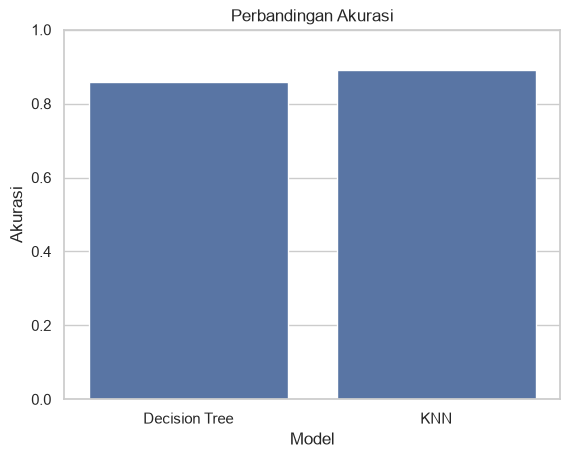

In [19]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
hasil = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Akurasi": [akurasi_dt_final, akurasi_knn_final]
})
print(hasil)

sns.barplot(x="Model", y="Akurasi", data=hasil)
plt.ylim(0, 1)
plt.title("Perbandingan Akurasi")
plt.show()

## Confusion matrix

NIM : 202531077_Syalwa Melza Eka Fitri


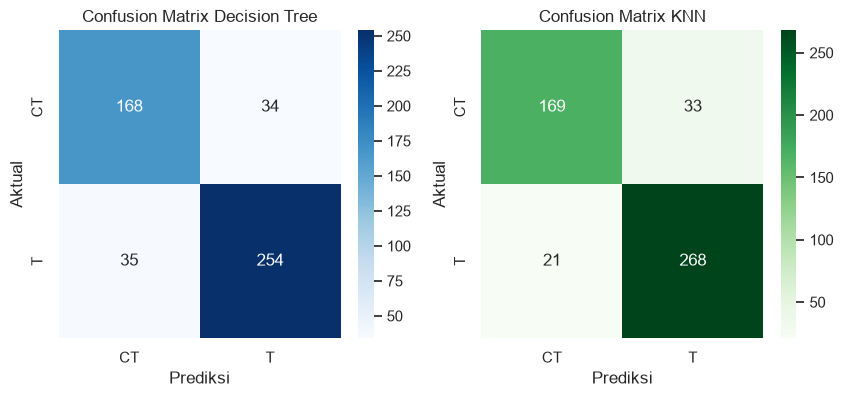

In [20]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_test, pred_dt), annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[0])
ax[0].set_title("Confusion Matrix Decision Tree")
ax[0].set_xlabel("Prediksi")
ax[0].set_ylabel("Aktual")

sns.heatmap(confusion_matrix(y_test, pred_knn), annot=True, fmt="d", cmap="Greens",
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[1])
ax[1].set_title("Confusion Matrix KNN")
ax[1].set_xlabel("Prediksi")
ax[1].set_ylabel("Aktual")

plt.show()

## Prediksi data baru

In [21]:
# 202531077_Syalwa Melza Eka Fitri
print("NIM :", nim)
#contoh kondisi: map de_mirage, sisa waktu 40 detik, bom sudah ditanam, tim T lebih unggul
data_baru = pd.DataFrame(0, index=[0], columns=x.columns)
data_baru["time_left"] = 40
data_baru["ct_score"] = 5
data_baru["t_score"] = 6
data_baru["bomb_planted"] = 1
data_baru["ct_health"] = 200
data_baru["t_health"] = 400
data_baru["ct_armor"] = 150
data_baru["t_armor"] = 300
data_baru["ct_money"] = 3000
data_baru["t_money"] = 5000
data_baru["ct_helmets"] = 2
data_baru["t_helmets"] = 4
data_baru["map_de_mirage"] = 1

print("Prediksi Decision Tree:", le.inverse_transform(dt.predict(data_baru)))
print("Prediksi KNN          :", le.inverse_transform(knn.predict(scaler.transform(data_baru))))

NIM : 202531077_Syalwa Melza Eka Fitri
Prediksi Decision Tree: ['T']
Prediksi KNN          : ['T']
